# Phase 4: Clustering (data mining)

**Goal:** group the 1,170 team-seasons by **playing style** with **K-means** (k chosen by elbow, silhouette,
Davies–Bouldin, Calinski–Harabasz, stability and how well the groups read as real ways of playing), and compare with
**hierarchical clustering (Ward)**.

Clustered on the **8 equal-weight style dimensions** from Phase 3 (dominance, pressing, counter, high line,
physical, set pieces, long shots, back three), so each way of playing counts once. Team strength (npxG, points) and
workload (matches, European games, short rest, rotation) are not clustered; they are shown next to each cluster, so
it is clear how far a style goes with strength or with load.

**Chosen with the user (2026-10-21):** k = 7 as the main clustering, k = 4 as a robustness check in Phase 5.

**Steps**
1. Style dimensions
2. K-means for k = 2…10: quality measures
3. Stability: overall (bootstrap ARI) and per cluster (bootstrap Jaccard)
4. Ward and agreement with K-means
5. Profiles of the main and check k: centroids, typical teams, strength, workload, leagues
6. Cluster names (rules agreed with the user), saved clusters
7. 2-D view of the chosen clustering (PCA, for visualisation only)
8. Report

**Input:** `data/03_features/` (style dimensions, features and roles), `us_team_matches` (points, for the strength check only).
**Outputs:** `data/04_clusters/`, `reports/04_clustering.md`, `reports/figures/04_*.png`.

In [1]:
import sys
from datetime import date
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.colors import LinearSegmentedColormap
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score, silhouette_score

sys.path.insert(0, str(Path.cwd().parent))  # project root, for the analysis package
from analysis.config import DATA_DIR, FIGURES_DIR, REPORTS_DIR, phase_dir
from analysis.load import league_from_understat, read_table
from analysis.report import md_table

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 120)

PHASE = "04_clusters"
OUT_DIR = phase_dir(PHASE)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
K_RANGE = range(2, 11)
N_INIT = 50  # K-means restarts per fit; the best (lowest inertia) is kept
N_BOOT = 50  # bootstrap resamples for stability
MIN_JACCARD = 0.6  # every cluster's mean bootstrap Jaccard at least this (Hennig 2007: < 0.5 dissolves, >= 0.6 a pattern)
MIN_SHARE = 0.03  # no cluster smaller than 3% of team-seasons
MAIN_K, CHECK_K = 7, 4  # agreed with the user after reading steps 2-5

# Chart palette: validated reference palette (dataviz skill), categorical slots in fixed order.
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
MARKERS = ["o", "s", "^", "D", "v", "P", "X", "*"]
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": MUTED, "axes.labelcolor": INK,
    "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "lines.linewidth": 2,
})


def save(fig, name: str) -> str:
    path = FIGURES_DIR / name
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(path)))
    return name

## Step 1. Style dimensions

The 8 equal-weight style dimensions from Phase 3 (each the mean of its features' signed z-scores, re-standardised).

In [2]:
features = pd.read_parquet(DATA_DIR / "03_features" / "team_season_features.parquet")
roles = pd.read_csv(DATA_DIR / "03_features" / "feature_roles.csv")
kept = roles[roles.status == "kept"]
STYLE = kept[kept.role == "style"].feature.tolist()
OUTCOME = kept[kept.role == "outcome"].feature.tolist()
EXPOSURE = kept[kept.role == "exposure"].feature.tolist()
style_dims = pd.read_parquet(DATA_DIR / "03_features" / "style_dimensions.parquet")
DIMS = [c for c in style_dims.columns if c not in ("league", "season", "season_key", "tm_club_id", "club")]
assert (style_dims[["season", "tm_club_id"]].to_numpy() == features[["season", "tm_club_id"]].to_numpy()).all()
X = style_dims[DIMS].to_numpy()
assert not np.isnan(X).any()
style_dims[DIMS].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
dominance,1170.0,-0.0,1.0,-2.20,-0.71,-0.21,0.61,4.22
pressing,1170.0,0.0,1.0,-3.52,-0.67,0.08,0.75,2.33
counter,1170.0,-0.0,1.0,-2.46,-0.71,-0.09,0.64,3.64
high_line,1170.0,-0.0,1.0,-2.35,-0.69,-0.07,0.60,6.44
physical,1170.0,-0.0,1.0,-2.70,-0.70,-0.04,0.66,2.99
set_pieces,1170.0,0.0,1.0,-3.33,-0.69,-0.05,0.66,3.56
long_shots,1170.0,-0.0,1.0,-2.63,-0.69,-0.06,0.69,2.90
back_three,1170.0,-0.0,1.0,-0.77,-0.76,-0.49,0.41,2.53


## Step 2. K-means for k = 2…10

For each k, K-means with 50 random starts (fixed seed); the best fit is kept. Four measures:
- **inertia** (within-cluster sum of squares): always falls with k; look for the elbow where it flattens;
- **silhouette** (−1…1, higher is better): how much closer a team-season is to its own cluster than to the next;
- **Davies–Bouldin** (lower is better): cluster spread relative to the distance between clusters;
- **Calinski–Harabasz** (higher is better): between-cluster vs within-cluster variance.

In [3]:
kmeans = {k: KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(X) for k in K_RANGE}
quality = pd.DataFrame([{
    "k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X, km.labels_),
    "davies_bouldin": davies_bouldin_score(X, km.labels_), "calinski_harabasz": calinski_harabasz_score(X, km.labels_),
    "smallest cluster": np.bincount(km.labels_).min(),
} for k, km in kmeans.items()])
quality.round(3)

,k,inertia,silhouette,davies_bouldin,calinski_harabasz,smallest cluster
0,2,7807.077,0.165,2.037,232.329,397
1,3,6745.593,0.155,1.896,226.149,300
2,4,6109.390,0.159,1.780,206.797,203
3,5,5760.288,0.142,1.833,182.008,194
4,6,5450.937,0.139,1.854,166.949,156
5,7,5190.729,0.127,1.852,155.690,114
6,8,5009.600,0.126,1.878,144.156,86
7,9,4843.200,0.123,1.868,135.345,79
8,10,4692.166,0.126,1.742,128.221,70


## Step 3. Stability

A clustering worth interpreting should not depend on which team-seasons happen to be in the data. For each k, K-means
is refitted on 50 bootstrap samples (drawn with replacement) and compared with the full-data clustering:
- **overall:** assign all team-seasons with the bootstrap fit; adjusted Rand index (ARI: 1 = identical, 0 = chance);
- **per cluster** (Hennig 2007): for each original cluster, the best Jaccard overlap with a bootstrap cluster, over the
  team-seasons in the sample. Mean Jaccard < 0.5 means the cluster dissolves; ≥ 0.6 a real pattern; ≥ 0.75 stable.

Finer typologies of a continuum are less stable overall, so a k is usable when **every** cluster reaches 0.6.

In [4]:
rng = np.random.default_rng(SEED)
boot_idx = [rng.integers(0, len(X), len(X)) for _ in range(N_BOOT)]


def bootstrap(k: int) -> tuple[list[float], np.ndarray]:
    """Overall ARI per resample, and mean Jaccard per original cluster."""
    ref = kmeans[k].labels_
    aris, jac = [], np.zeros((len(boot_idx), k))
    for b, idx in enumerate(boot_idx):
        fit = KMeans(n_clusters=k, n_init=10, random_state=SEED + b).fit(X[idx])
        aris.append(adjusted_rand_score(ref, fit.predict(X)))
        inside = np.unique(idx)
        a, bl = ref[inside], fit.predict(X[inside])
        both = np.zeros((k, k))
        np.add.at(both, (a, bl), 1)
        size_a, size_b = both.sum(axis=1, keepdims=True), both.sum(axis=0, keepdims=True)
        jac[b] = (both / (size_a + size_b - both)).max(axis=1)
    return aris, jac.mean(axis=0)


boot = {k: bootstrap(k) for k in K_RANGE}
cluster_jaccard = {k: j for k, (_, j) in boot.items()}
stability = pd.DataFrame([{"k": k, "stability (mean ARI)": np.mean(a), "min cluster Jaccard": j.min(),
                           "clusters < 0.6": int((j < MIN_JACCARD).sum())} for k, (a, j) in boot.items()])
stability.round(3)

,k,stability (mean ARI),min cluster Jaccard,clusters < 0.6
0,2,0.817,0.872,0
1,3,0.881,0.918,0
2,4,0.863,0.888,0
3,5,0.648,0.527,1
4,6,0.609,0.528,2
5,7,0.654,0.610,0
6,8,0.556,0.484,4
7,9,0.512,0.422,7
8,10,0.497,0.346,7


## Step 4. Ward and agreement with K-means

Hierarchical clustering with Ward linkage (merges the pair of clusters that least increases within-cluster variance,
the criterion K-means minimises) is cut at each k and compared with K-means by ARI.

In [5]:
ward = {k: AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X) for k in K_RANGE}
agreement = pd.DataFrame([{"k": k, "Ward vs K-means (ARI)": adjusted_rand_score(kmeans[k].labels_, ward[k]),
                           "Ward silhouette": silhouette_score(X, ward[k])} for k in K_RANGE])
summary = quality.merge(stability, on="k").merge(agreement, on="k")
summary["usable"] = (summary["min cluster Jaccard"] >= MIN_JACCARD) & (summary["smallest cluster"] >= MIN_SHARE * len(X)) & (summary.k >= 3)
summary.round(3)

,k,inertia,silhouette,davies_bouldin,calinski_harabasz,smallest cluster,stability (mean ARI),min cluster Jaccard,clusters < 0.6,Ward vs K-means (ARI),Ward silhouette,usable
0,2,7807.077,0.165,2.037,232.329,397,0.817,0.872,0,0.343,0.124,False
1,3,6745.593,0.155,1.896,226.149,300,0.881,0.918,0,0.256,0.141,True
2,4,6109.390,0.159,1.780,206.797,203,0.863,0.888,0,0.456,0.115,True
3,5,5760.288,0.142,1.833,182.008,194,0.648,0.527,1,0.377,0.093,False
4,6,5450.937,0.139,1.854,166.949,156,0.609,0.528,2,0.321,0.079,False
5,7,5190.729,0.127,1.852,155.690,114,0.654,0.610,0,0.361,0.072,True
6,8,5009.600,0.126,1.878,144.156,86,0.556,0.484,4,0.347,0.072,False
7,9,4843.200,0.123,1.868,135.345,79,0.512,0.422,7,0.341,0.075,False
8,10,4692.166,0.126,1.742,128.221,70,0.497,0.346,7,0.319,0.077,False


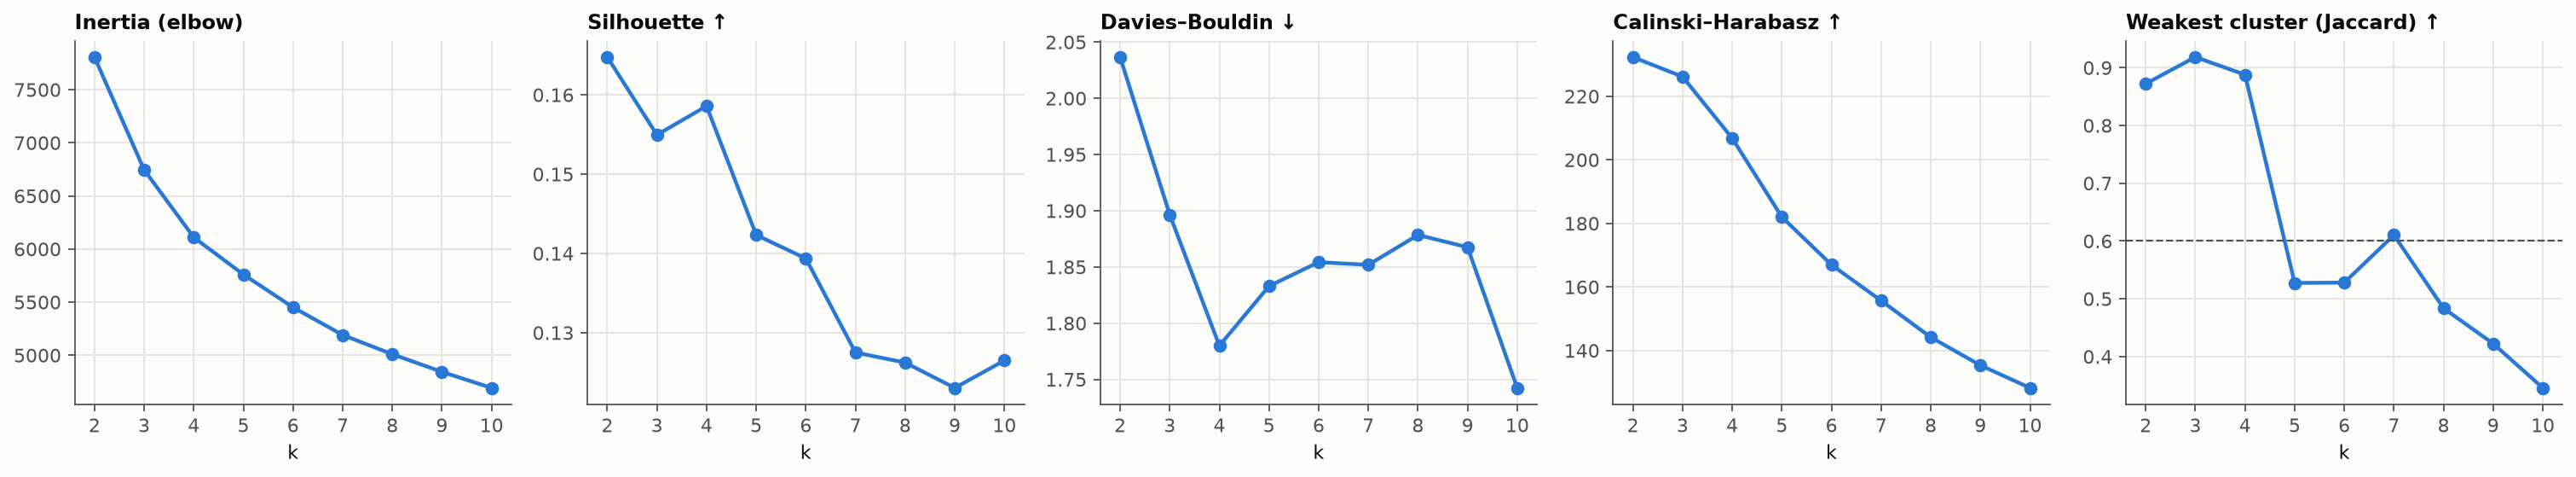

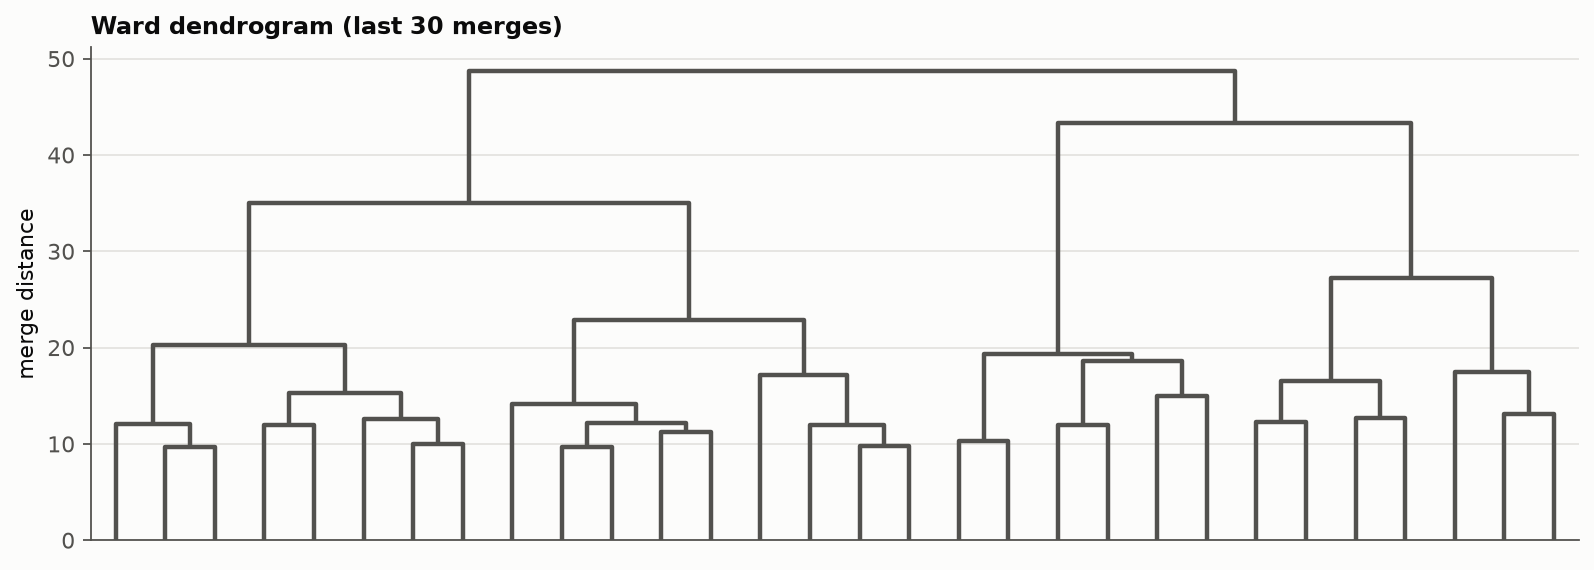

In [6]:
# Figure: the measures against k (one series), and the Ward dendrogram.
fig, axes = plt.subplots(1, 5, figsize=(19, 3.6))
measures = [("inertia", "Inertia (elbow)"), ("silhouette", "Silhouette ↑"), ("davies_bouldin", "Davies–Bouldin ↓"),
            ("calinski_harabasz", "Calinski–Harabasz ↑"), ("min cluster Jaccard", "Weakest cluster (Jaccard) ↑")]
for ax, (col, title) in zip(axes, measures):
    ax.plot(summary.k, summary[col], color=SERIES[0], marker="o", markersize=6)
    ax.set_title(title, loc="left")
    ax.set_xlabel("k")
    ax.set_xticks(list(K_RANGE))
axes[4].axhline(MIN_JACCARD, color=MUTED, linewidth=1, linestyle="--")
fig.tight_layout()
quality_fig = save(fig, "04_k_selection.png")

fig, ax = plt.subplots(figsize=(12, 4))
dendrogram(linkage(X, method="ward"), truncate_mode="lastp", p=30, ax=ax, color_threshold=0,
           above_threshold_color=MUTED, no_labels=True)
ax.set_title("Ward dendrogram (last 30 merges)", loc="left")
ax.set_ylabel("merge distance")
ax.grid(axis="x", visible=False)
dendro_fig = save(fig, "04_dendrogram.png")

## Step 5. Profiles of the main and check k

For k = 7 (main) and k = 4 (check): sizes, centroids on the style dimensions, per-cluster stability, the four
team-seasons closest to each centroid, and next to them **team strength** (points and npxG per match), **workload**
and the **league mix**.

In [7]:
um = read_table("us_team_matches")
points = (um.assign(league=um.league.map(league_from_understat), season=um.season.astype(int), pts=um.pts.astype(float))
          .groupby(["league", "season", "team_id"]).pts.mean().rename("points_pm").reset_index()
          .rename(columns={"team_id": "us_team_id"}))
keys = pd.read_csv(DATA_DIR / "01_entities" / "team_seasons.csv", dtype={"tm_club_id": str, "us_team_id": str})
base = features.join(style_dims[DIMS]).merge(keys[["league", "season", "tm_club_id", "us_team_id"]], on=["league", "season", "tm_club_id"]).merge(
    points, on=["league", "season", "us_team_id"], how="left")
assert base.points_pm.notna().all() and len(base) == len(X)


def eta_squared(values: pd.Series, groups: pd.Series) -> float:
    """Share of the variance of `values` explained by the groups (0 = none, 1 = all)."""
    grand = values.mean()
    between = sum(len(v) * (v.mean() - grand) ** 2 for _, v in values.groupby(groups))
    return between / ((values - grand) ** 2).sum()


def profile(k: int) -> dict:
    labels = kmeans[k].labels_
    df = base.assign(cluster=labels + 1)
    dist = np.linalg.norm(X - kmeans[k].cluster_centers_[labels], axis=1)
    examples = (df.assign(dist=dist).sort_values("dist").groupby("cluster").head(4)
                .assign(team=lambda d: d.club + " " + d.season_key).groupby("cluster").team.apply(", ".join))
    g = df.groupby("cluster")
    context = pd.concat([g.size().rename("n"), pd.Series(cluster_jaccard[k].round(2), index=range(1, k + 1), name="Jaccard"),
                         g.points_pm.mean().round(2).rename("points/match"),
                         g.npxg_pm.mean().round(2).rename("npxG/match"), g[EXPOSURE].mean().round(2)], axis=1)
    return {
        "df": df,
        "centroid_z": g[DIMS].mean(),
        "centroid_raw": g[STYLE].mean(),
        "context": context,
        "examples": examples,
        "leagues": pd.crosstab(df.cluster, df.league, normalize="index").round(2),
        "seasons": pd.crosstab(df.season_key, df.cluster, normalize="index").round(2),
        "eta2_points": eta_squared(df.points_pm, df.cluster),
    }


USABLE = summary[summary.usable].k.tolist()
assert MAIN_K in USABLE and CHECK_K in USABLE, f"usable k changed: {USABLE}"
profiles = {k: profile(k) for k in (MAIN_K, CHECK_K)}
print("usable k:", USABLE, "| profiled:", list(profiles))
pd.DataFrame({k: {"share of points variance explained (eta²)": round(p["eta2_points"], 2)} for k, p in profiles.items()}).T

usable k: [3, 4, 7] | profiled: [7, 4]


,share of points variance explained (eta²)
7,0.41
4,0.33


In [8]:
# Check: for the main and check k, the style centroids, typical teams, strength, workload and leagues.
for k, p in profiles.items():
    print(f"\n==================== k = {k} ====================")
    display(p["centroid_z"].round(1))
    display(pd.concat([p["context"], p["examples"].rename("closest to centroid")], axis=1))
    display(p["leagues"])


==================== k = 7 ====================


,dominance,pressing,counter,high_line,physical,set_pieces,long_shots,back_three
cluster,,,,,,,,
1,-0.2,0.8,0.1,0.7,1.0,0.9,0.2,-0.5
2,0.7,0.4,-0.3,-0.4,-0.2,-0.7,-0.4,-0.4
3,-0.5,0.4,-0.3,-0.1,0.7,-0.3,1.3,-0.3
4,0.1,-0.4,-0.2,-0.2,-0.1,-0.1,-0.5,2.0
5,-0.7,-0.7,1.6,-0.5,-0.0,-0.3,0.2,-0.2
6,1.9,0.9,-0.6,1.2,-1.1,-0.8,-0.8,-0.3
7,-0.6,-1.0,-0.1,-0.2,-0.6,0.7,-0.2,-0.3


,n,Jaccard,points/match,npxG/match,matches_all,matches_europe,short_rest_share,rest_sd,top14_share,closest to centroid
1,178,0.68,1.29,1.17,43.69,2.84,0.21,3.28,0.80,"Cagliari Calcio 2018-19, Real Sociedad 2025-26, AS Monaco 2017-18, CA Osasuna 2019-20"
2,175,0.66,1.72,1.51,49.29,7.29,0.28,3.17,0.80,"Chelsea FC 2025-26, Stade Reims 2023-24, LOSC Lille 2021-22, Athletic Bilbao 2025-26"
3,178,0.64,1.20,1.04,42.56,1.56,0.18,3.33,0.79,"GFC Ajaccio 2015-16, SM Caen 2017-18, FC Metz 2017-18, Torino FC 2016-17"
4,166,0.84,1.40,1.34,44.31,4.01,0.19,3.16,0.81,"1.FSV Mainz 05 2022-23, FC Toulouse 2025-26, Clermont Foot 63 2022-23, Wolverhampton Wanderers 2024-25"
5,132,0.61,1.13,1.11,40.86,1.30,0.15,3.28,0.79,"Hertha BSC 2019-20, UD Almería 2023-24, Angers SCO 2022-23, Hertha BSC 2020-21"
6,114,0.80,2.04,1.94,52.74,9.71,0.31,3.04,0.81,"Paris Saint-Germain 2021-22, Brighton & Hove Albion 2022-23, Borussia Dortmund 2020-21, FC Barcelona 2025-26"
7,227,0.71,1.11,1.11,42.00,1.36,0.17,3.26,0.80,"Aston Villa 2021-22, FC Nantes 2022-23, VfL Wolfsburg 2024-25, Everton FC 2023-24"


league,Bundesliga,La Liga,Ligue 1,Premier League,Serie A
cluster,,,,,
1,0.23,0.46,0.20,0.04,0.08
2,0.09,0.27,0.22,0.23,0.19
3,0.07,0.21,0.25,0.08,0.38
4,0.23,0.05,0.14,0.13,0.46
5,0.24,0.19,0.27,0.14,0.16
6,0.23,0.13,0.16,0.40,0.08
7,0.22,0.11,0.18,0.40,0.08



==================== k = 4 ====================


,dominance,pressing,counter,high_line,physical,set_pieces,long_shots,back_three
cluster,,,,,,,,
1,-0.6,-0.9,0.4,-0.4,-0.4,0.3,-0.0,-0.4
2,0.0,-0.5,-0.1,-0.2,-0.0,-0.0,-0.5,1.8
3,-0.3,0.7,0.0,0.1,0.9,0.2,0.8,-0.4
4,1.3,0.7,-0.4,0.6,-0.7,-0.7,-0.6,-0.3


,n,Jaccard,points/match,npxG/match,matches_all,matches_europe,short_rest_share,rest_sd,top14_share,closest to centroid
1,364,0.89,1.15,1.12,41.93,1.45,0.17,3.26,0.80,"Deportivo Alavés 2023-24, Valencia CF 2025-26, Tottenham Hotspur 2020-21, Borussia Mönchengladbach 2014-15"
2,203,0.92,1.34,1.31,43.51,3.59,0.18,3.17,0.81,"Clermont Foot 63 2022-23, FC Toulouse 2025-26, Wolverhampton Wanderers 2024-25, 1.FSV Mainz 05 2022-23"
3,345,0.90,1.28,1.11,43.72,2.59,0.20,3.31,0.79,"AS Monaco 2018-19, UD Las Palmas 2016-17, Getafe CF 2015-16, Cagliari Calcio 2018-19"
4,258,0.91,1.85,1.72,50.76,8.36,0.29,3.11,0.81,"Paris Saint-Germain 2021-22, Arsenal FC 2016-17, Juventus FC 2024-25, Chelsea FC 2022-23"


league,Bundesliga,La Liga,Ligue 1,Premier League,Serie A
cluster,,,,,
1,0.20,0.14,0.23,0.32,0.12
2,0.28,0.05,0.13,0.12,0.42
3,0.12,0.39,0.22,0.04,0.23
4,0.18,0.18,0.19,0.33,0.12


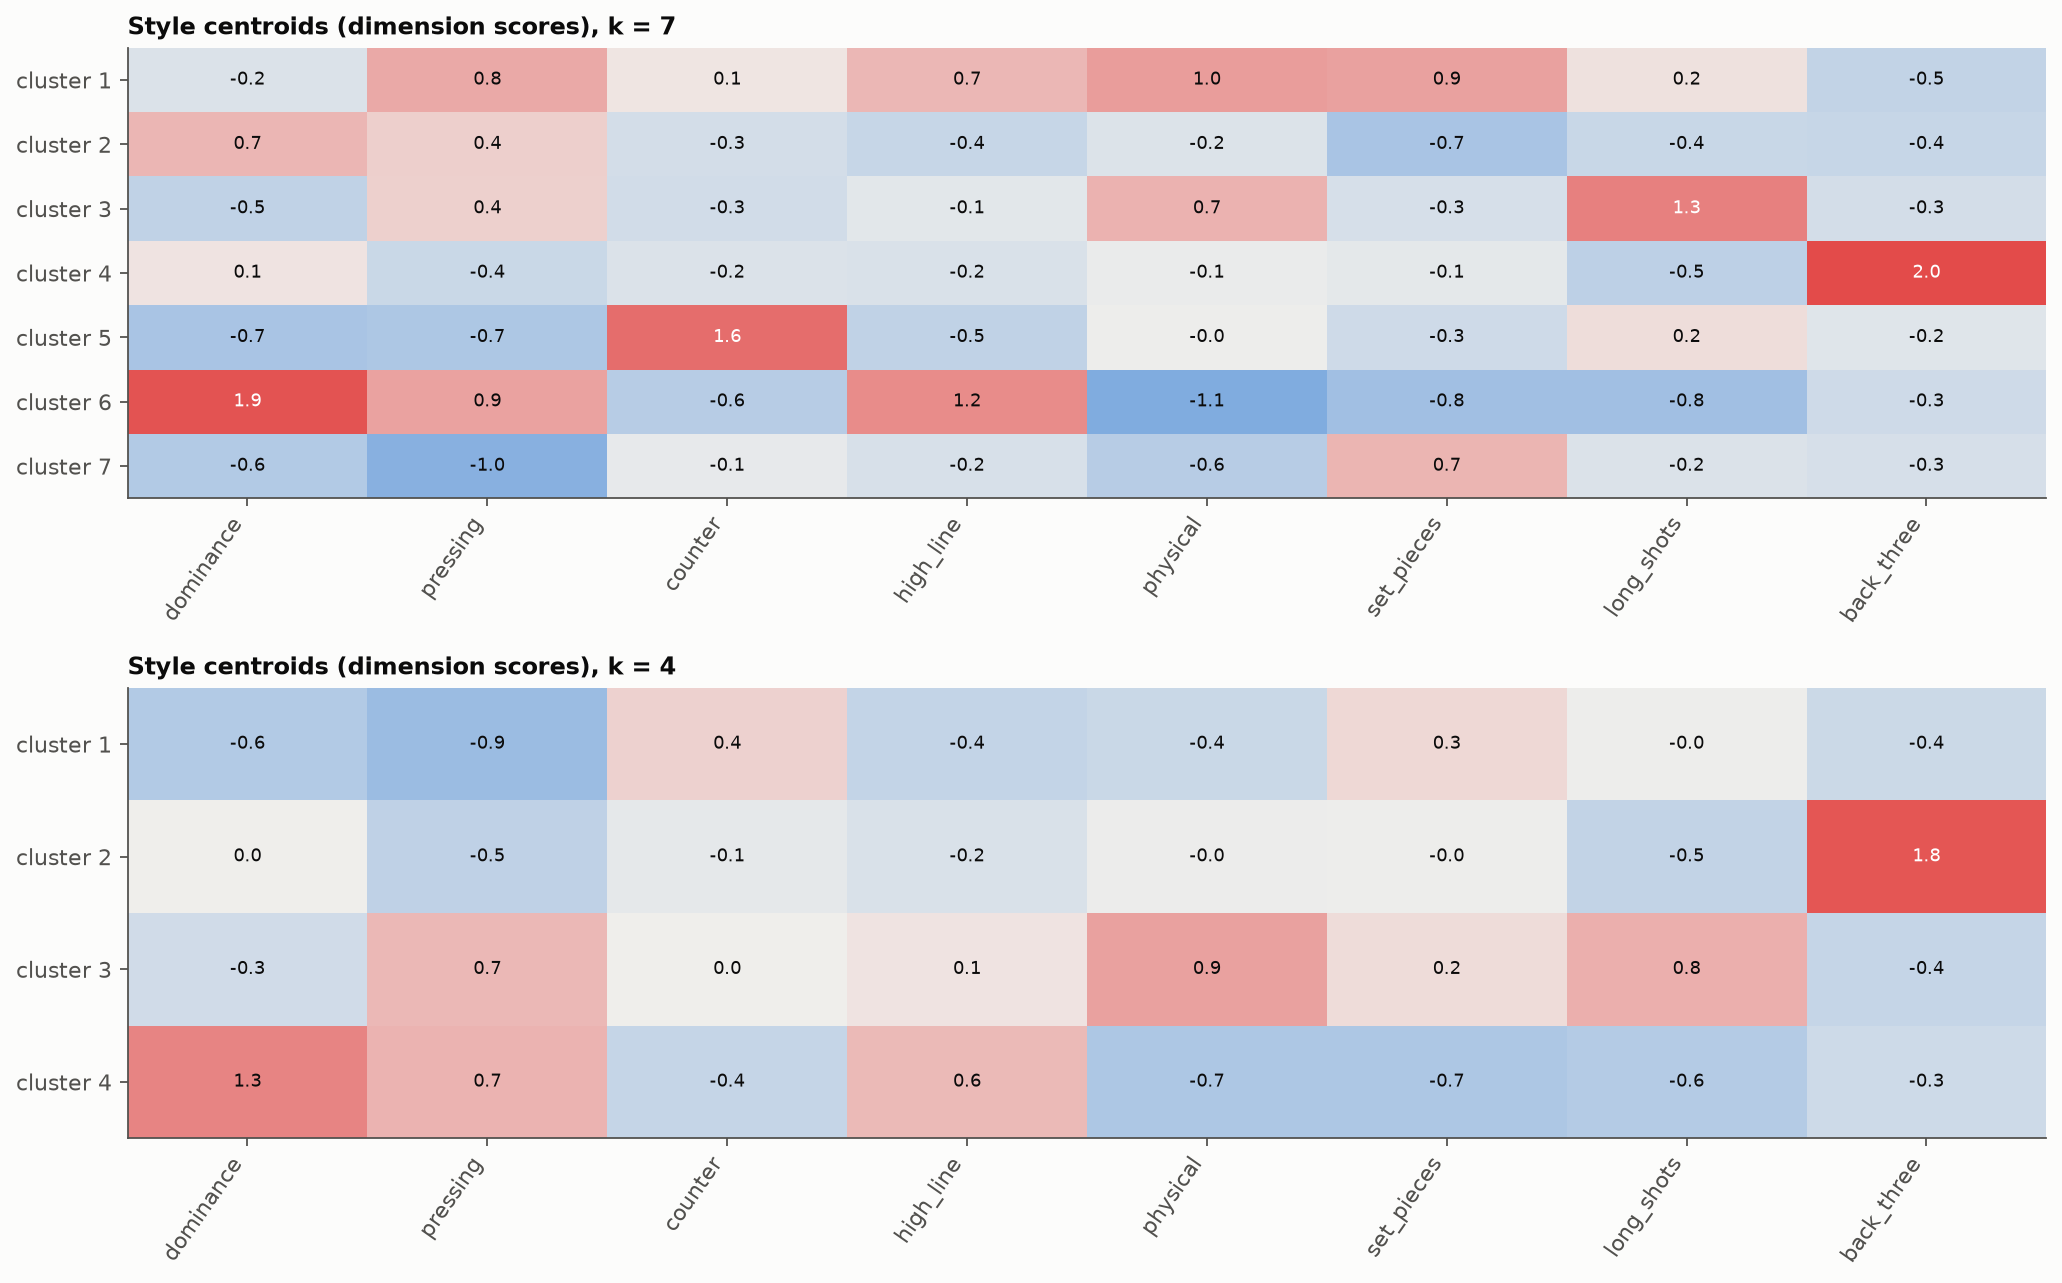

In [9]:
# Figure: style centroid heatmaps (z-scores; blue = below average, red = above), one per usable k.
def heatmap(ax, cz: pd.DataFrame, title: str, names: dict | None = None) -> None:
    ax.imshow(cz.to_numpy(), cmap=DIVERGING, vmin=-2, vmax=2, aspect="auto")
    ax.set_xticks(range(cz.shape[1]), cz.columns, rotation=55, ha="right")
    ax.set_yticks(range(cz.shape[0]), [f"{c} {names[c]}" if names else f"cluster {c}" for c in cz.index])
    ax.grid(False)
    for (i, j), v in np.ndenumerate(cz.to_numpy()):
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 1.3 else INK)
    ax.set_title(title, loc="left")


fig, axes = plt.subplots(len(profiles), 1, figsize=(13, sum(0.45 * k + 1.6 for k in profiles)), squeeze=False)
for ax, (k, p) in zip(axes[:, 0], profiles.items()):
    heatmap(ax, p["centroid_z"], f"Style centroids (dimension scores), k = {k}", names=None)
fig.tight_layout()
heat_fig = save(fig, "04_centroids_by_k.png")

## Step 6. Cluster names and saved clusters

Names are given **by rule**, so they stay attached to the right cluster even if the numbering of K-means changes:
the rules are applied in order, each picking among the clusters not yet named (agreed with the user, 2026-10-21).

In [10]:
NAMING = {
    7: [("Elite dominance", "dominance", "max"), ("Back three", "back_three", "max"), ("Counter-attacking", "counter", "max"),
        ("Direct and physical", "long_shots", "max"), ("Passive low block", "pressing", "min"),
        ("Aggressive press and set pieces", "set_pieces", "max"), ("Controlled possession", None, None)],
    4: [("Back three", "back_three", "max"), ("Dominant pressing", "dominance", "max"),
        ("Passive low block", "pressing", "min"), ("Direct and physical", None, None)],
}


def name_clusters(centroids: pd.DataFrame, rules: list) -> dict[int, str]:
    remaining, names = list(centroids.index), {}
    for name, dim, how in rules:
        if dim is None:
            assert len(remaining) == 1
            pick = remaining[0]
        else:
            col = centroids.loc[remaining, dim]
            pick = col.idxmax() if how == "max" else col.idxmin()
        names[pick] = name
        remaining.remove(pick)
    return names


NAMES = {k: name_clusters(profiles[k]["centroid_z"], NAMING[k]) for k in (MAIN_K, CHECK_K)}
main, check = profiles[MAIN_K]["df"], profiles[CHECK_K]["df"]
out = main[["league", "season", "season_key", "tm_club_id", "club"]].assign(
    cluster=main.cluster, cluster_name=main.cluster.map(NAMES[MAIN_K]),
    cluster_k4=check.cluster, cluster_k4_name=check.cluster.map(NAMES[CHECK_K]))
assert out.notna().all().all()
out.to_parquet(OUT_DIR / "team_season_clusters.parquet", index=False)
summary.to_csv(OUT_DIR / "k_selection.csv", index=False)
print("saved", len(out), "team-season clusters")
pd.crosstab(out.cluster_name, out.cluster_k4_name)

saved 1170 team-season clusters


cluster_k4_name,Back three,Direct and physical,Dominant pressing,Passive low block
cluster_name,,,,
Aggressive press and set pieces,4,148,18,8
Back three,162,0,4,0
Controlled possession,2,26,112,35
Counter-attacking,13,17,2,100
Direct and physical,5,154,2,17
Elite dominance,0,0,114,0
Passive low block,17,0,6,204


## Step 7. 2-D view of the chosen clustering

PCA projects the style features onto the two directions of largest variance, **only to draw** the clusters
(clustering uses all style features). Marker shapes and numbered labels carry cluster identity alongside colour.

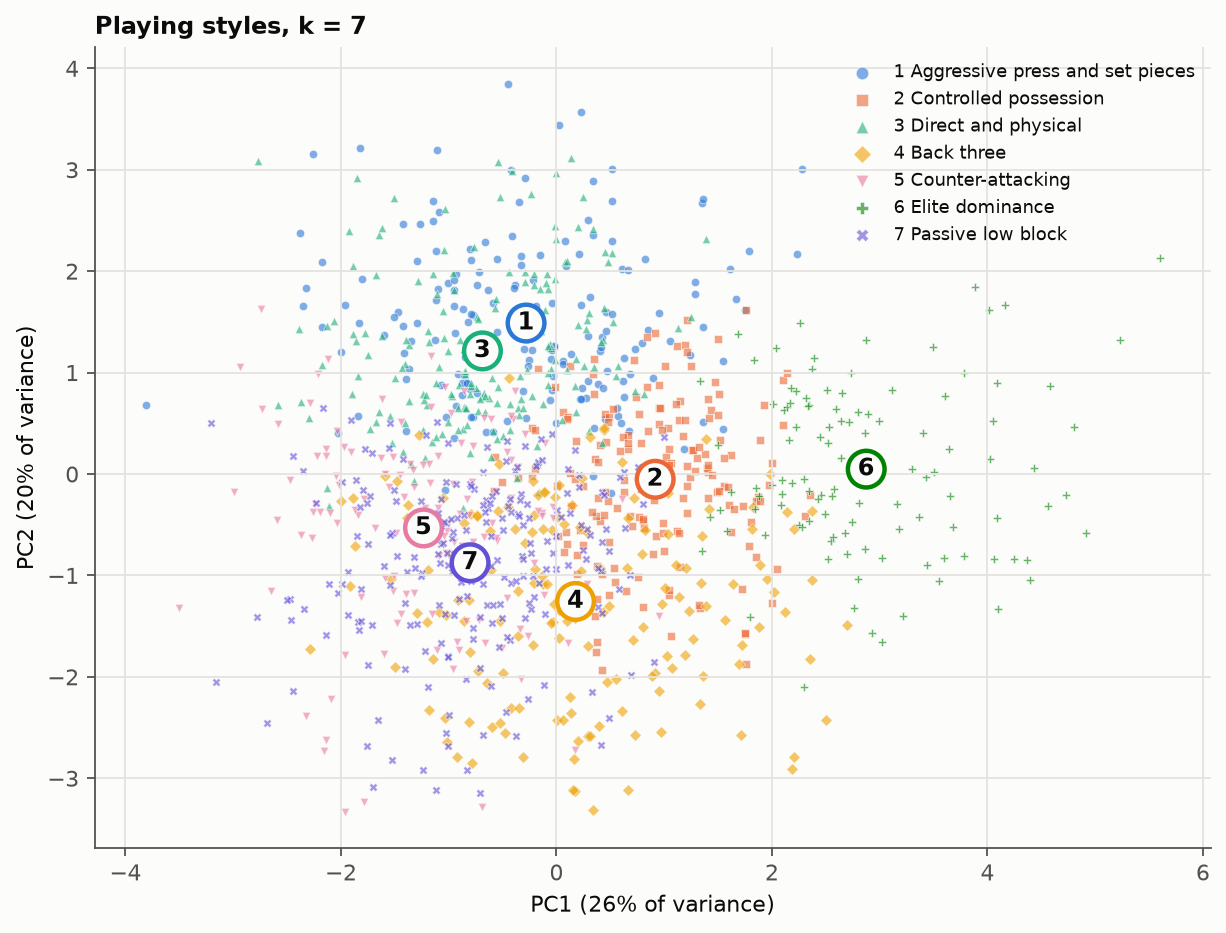

In [11]:
if True:
    p = profiles[MAIN_K]
    xy = PCA(n_components=2, random_state=SEED).fit(X)
    ev, xy = xy.explained_variance_ratio_, xy.transform(X)
    fig, ax = plt.subplots(figsize=(9, 6.5))
    for c in sorted(p["df"].cluster.unique()):
        m = p["df"].cluster.to_numpy() == c
        ax.scatter(xy[m, 0], xy[m, 1], s=14, color=SERIES[c - 1], marker=MARKERS[c - 1], alpha=0.6,
                   edgecolors=SURFACE, linewidths=0.4, label=f"{c} {NAMES[MAIN_K][c]}")
        cx, cy = xy[m].mean(axis=0)
        ax.text(cx, cy, str(c), ha="center", va="center", fontsize=11, fontweight="bold", color=INK,
                bbox={"boxstyle": "circle,pad=0.25", "facecolor": SURFACE, "edgecolor": SERIES[c - 1], "linewidth": 2})
    ax.set_xlabel(f"PC1 ({ev[0]:.0%} of variance)")
    ax.set_ylabel(f"PC2 ({ev[1]:.0%} of variance)")
    ax.set_title(f"Playing styles, k = {MAIN_K}", loc="left")
    ax.legend(frameon=False, fontsize=8, markerscale=1.5, loc="best")
    pca_fig = save(fig, "04_pca.png")

## Step 8. Report

In [12]:
cols = ["k", "silhouette", "davies_bouldin", "calinski_harabasz", "stability (mean ARI)", "min cluster Jaccard",
        "Ward vs K-means (ARI)", "smallest cluster", "usable"]
text = [
    "# Phase 4: Clustering",
    "",
    f"Generated {date.today().isoformat()} by `notebooks/04_clustering.ipynb`, where each step is shown with its checks.",
    "",
    "## Status",
    "",
    f"Main clustering **k = {MAIN_K}**: " + ", ".join(f"{c} {n}" for c, n in sorted(NAMES[MAIN_K].items())) + ". "
    f"Robustness check **k = {CHECK_K}**: " + ", ".join(f"{c} {n}" for c, n in sorted(NAMES[CHECK_K].items())) + ".",
    "",
    f"Clustered on {len(DIMS)} equal-weight style dimensions ({', '.join(DIMS)}), built in Phase 3 from {len(STYLE)} "
    "style features. Team strength and workload are shown, not clustered. Usable k (every cluster Jaccard ≥ 0.6, no "
    f"cluster under 3%): {USABLE}.",
    "",
    "## 1. Choosing k",
    "",
    md_table(summary[cols].round(3), index=False),
    "",
    f"![k selection](figures/{quality_fig})",
    "",
    f"![Ward dendrogram](figures/{dendro_fig})",
    "",
    "## 2. Profiles",
    "",
]
for k, p in profiles.items():
    names = NAMES[k]
    ctx = pd.concat([p["context"], p["examples"].rename("closest to centroid")], axis=1)
    if names:
        ctx.insert(0, "name", ctx.index.map(names))
    text += [
        f"### k = {k} ({'main' if k == MAIN_K else 'robustness check'})",
        "",
        f"Share of team strength (points per match) explained by the clusters: eta² = {p['eta2_points']:.2f}.",
        "",
        md_table(ctx.rename_axis("cluster")),
        "",
        "Centroids on the style dimensions:",
        "",
        md_table(p["centroid_z"].round(2).T.rename_axis("feature")),
        "",
        "League mix (share of each cluster):",
        "",
        md_table(p["leagues"].rename_axis("cluster")),
        "",
    ]
text += ["How the seven styles sit inside the four (team-seasons):", "",
         md_table(pd.crosstab(out.cluster_name, out.cluster_k4_name).rename_axis("k = 7 vs k = 4")), "",
         f"![Centroids](figures/{heat_fig})", "", f"![PCA view](figures/{pca_fig})", ""]
(REPORTS_DIR / "04_clustering.md").write_text("\n".join(text), encoding="utf-8")
print("wrote", REPORTS_DIR / "04_clustering.md")

wrote /Users/mohammadshweiki/Downloads/coding-projects/football-injuries/reports/04_clustering.md
